# Parkinson's Handwriting Analysis (pixel units, step by step)

This notebook extracts handwriting features associated with Parkinson's disease (PD) from a scanned sample. 

**All measurements are in pixels (px).** Every image is resized to the same width first, pixel values are comparable between samples scanned at a similar scale.

At the end there are three separate result plots:

1. **Traces**: the pen skeleton coloured by stroke width
2. **Word distance**: the gaps between words / letter groups, labelled in px
3. **Slope**: the fitted baseline of each line, labelled with its angle



## 1. Imports
| Library | Used for |
|---|---|
| `cv2` (OpenCV) | loading, thresholding, connected components |
| `numpy` | array maths |
| `skimage.morphology.skeletonize` | thinning strokes to 1 px centre lines |
| `scipy.stats` | linear regression (baseline, micrographia trend) |
| `scipy.signal.find_peaks` | detecting tremor-like curvature spikes |
| `matplotlib` | all plots |

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage.morphology import skeletonize
from scipy import stats
from scipy.signal import find_peaks

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 9})

## 2. Settings
- `IMAGE_PATH`: your handwriting scan.
- `TARGET_W`: every image is resized to this width so pixel measurements are comparable.
- `MIN_BLOB_AREA`: skeleton blobs with fewer pixels than this are treated as noise specks.
- `MIN_GAP_PX`: gaps this narrow or narrower are ignored (touching letters).

In [47]:
IMAGE_PATH = r"C:\Users\Ravideep\Desktop\h1.png"   # <- change to your image
TARGET_W  = 1200               
MIN_BLOB_AREA = 20                
MIN_GAP_PX = 2            

### Plot helper
A small function so every image plot looks the same (wide figure, no axes, height scaled to the image).

In [48]:
def show_image(image, title, cmap="gray", ax=None, colorbar=False, vmin=None, vmax=None):
    # Display one image with a title; returns the axis so extra layers can be drawn on it.
    if ax is None:
        h, w = image.shape[:2]
        _, ax = plt.subplots(figsize=(14, max(2.5, 14 * h / w)))
    im = ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.axis("off")
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
    return ax

## 3. Load and resize
Load the scan in grayscale and resize it to "TARGET_W" pixels wide, keeping the aspect ratio.

Original: 502 x 337 px  ->  resized: 1200 x 805 px


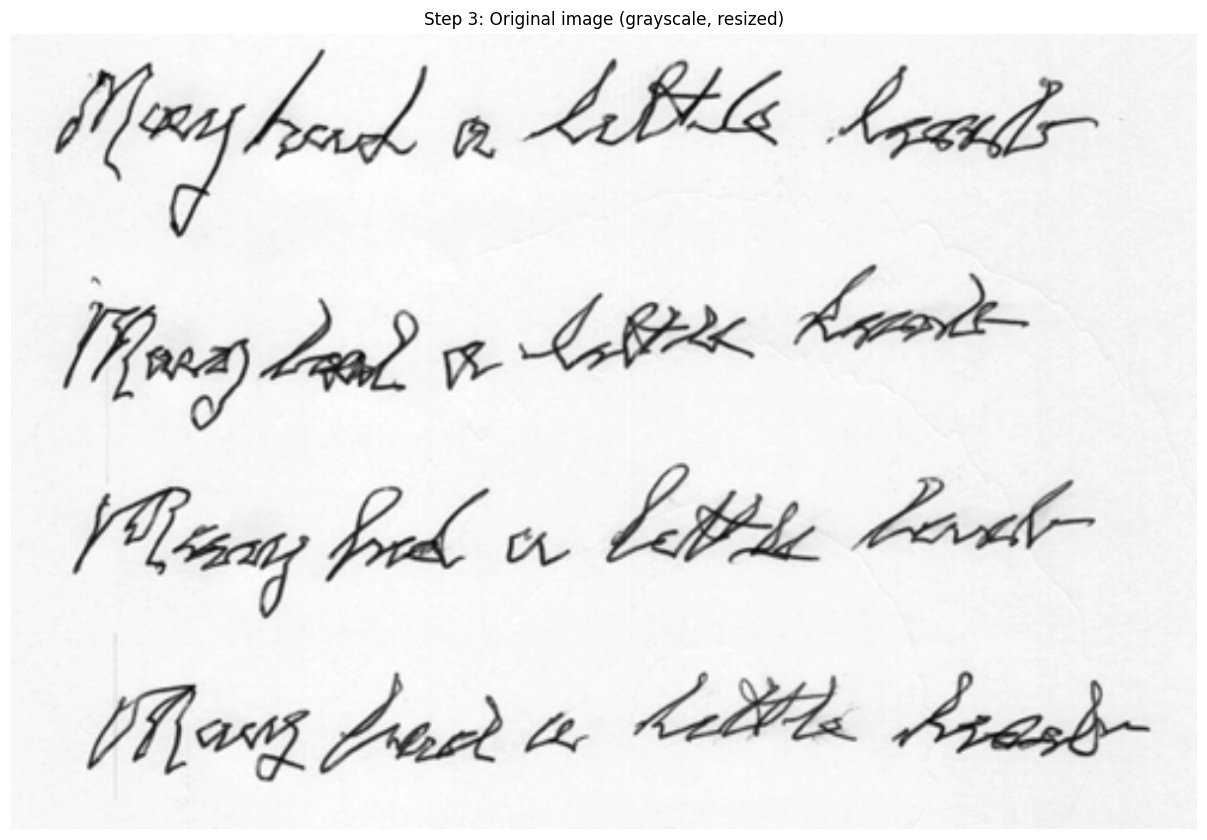

In [49]:
img_raw = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
if img_raw is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")

img = cv2.resize(img_raw, (TARGET_W, int(img_raw.shape[0] * TARGET_W / img_raw.shape[1])))
print(f"Original: {img_raw.shape[1]} x {img_raw.shape[0]} px  ->  resized: {img.shape[1]} x {img.shape[0]} px")

show_image(img, "Step 3: Original image (grayscale, resized)")
plt.show()

## 4. Binarise (separate ink from paper)
- **Otsu threshold, inverted**: ink becomes white (255), paper black (0). Otsu chooses the threshold automatically from the histogram.
- **Morphological close** with a 2x2 kernel fills tiny holes and breaks inside strokes.

The left plot shows the grayscale histogram with the threshold Otsu picked; the right plot shows the result.

Otsu threshold: 187  |  ink pixels: 74227


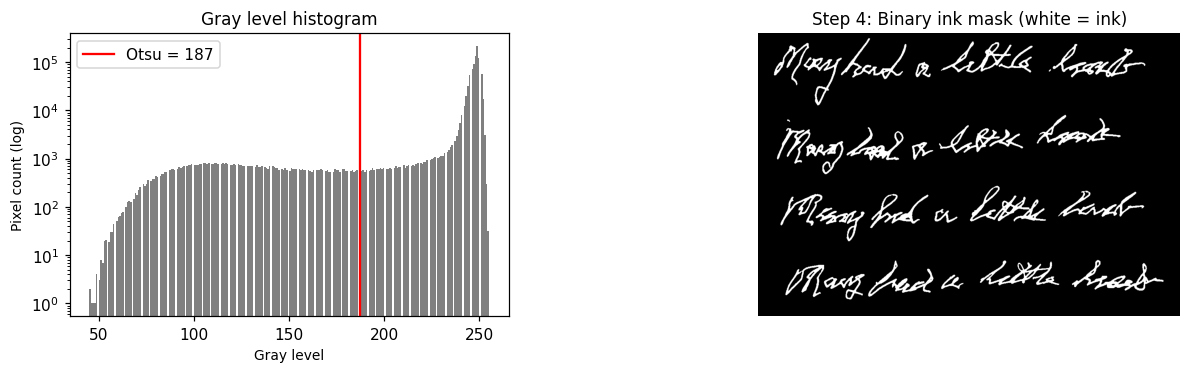

In [50]:
otsu_thresh, bw = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, np.ones((2, 2), np.uint8))
print(f"Otsu threshold: {otsu_thresh:.0f}  |  ink pixels: {(bw > 0).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 3.5), gridspec_kw={"width_ratios": [1, 3]})
axes[0].hist(img.ravel(), bins=256, color="gray")
axes[0].axvline(otsu_thresh, color="red", label=f"Otsu = {otsu_thresh:.0f}")
axes[0].set_yscale("log"); axes[0].set_xlabel("Gray level"); axes[0].set_ylabel("Pixel count (log)")
axes[0].set_title("Gray level histogram"); axes[0].legend()
show_image(bw, "Step 4: Binary ink mask (white = ink)", ax=axes[1])
plt.tight_layout(); plt.show()

## 5. Skeleton (the pen trace)
skeletonize thins every stroke to a 1 px wide centre line. This is the best estimate of the path the pen tip followed.

Skeleton pixels: 11124


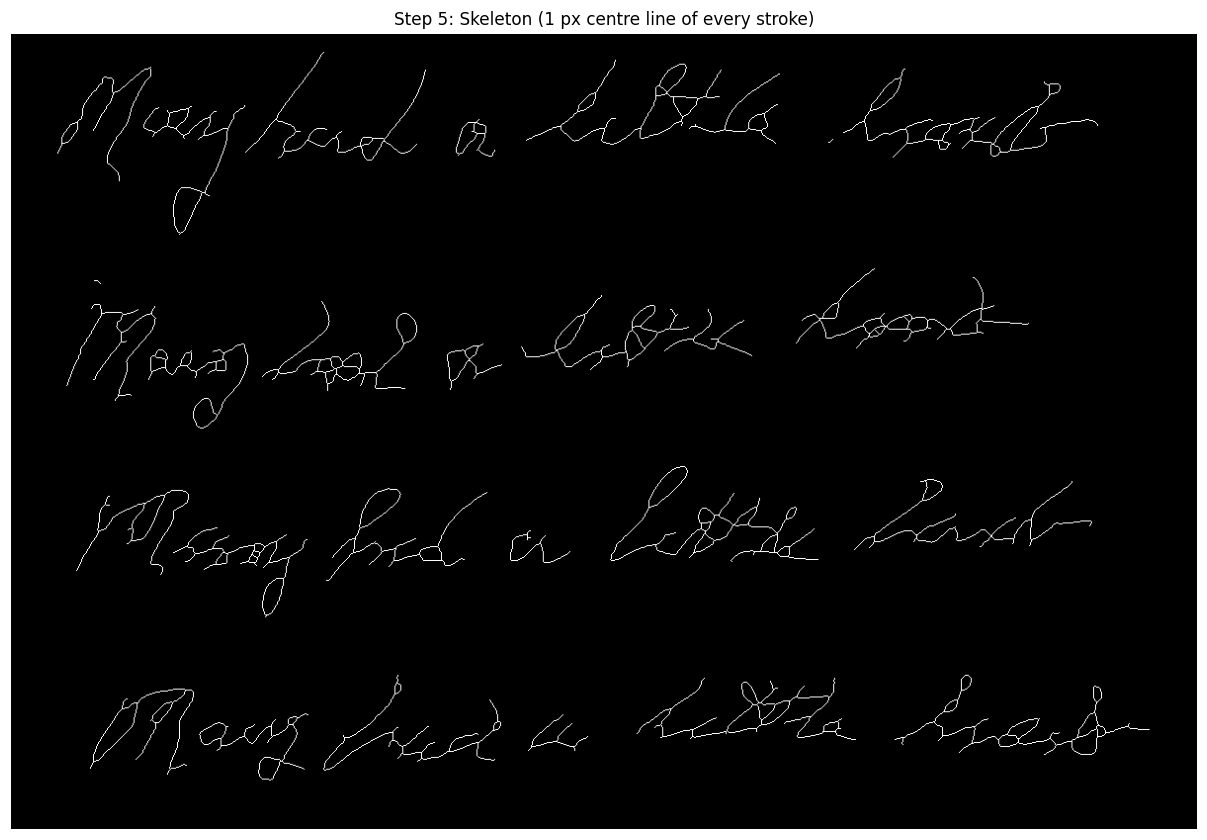

In [51]:
skeleton = (skeletonize(bw // 255) * 255).astype(np.uint8)
y_all, x_all = np.nonzero(skeleton)
print(f"Skeleton pixels: {len(x_all)}")

show_image(skeleton, "Step 5: Skeleton (1 px centre line of every stroke)")
plt.show()

## 6. Stroke width via distance transform
The distance transform gives each ink pixel its distance to the nearest paper pixel (black background). Sampled on the skeleton, that distance is half the local stroke width, so:

$$\text{stroke width (px)} = 2 \times \text{distance at skeleton pixel}$$

Left: the full distance map (bright = deep inside a thick stroke). Right: histogram of stroke width over all skeleton pixels.

Median stroke width: 6.00 px


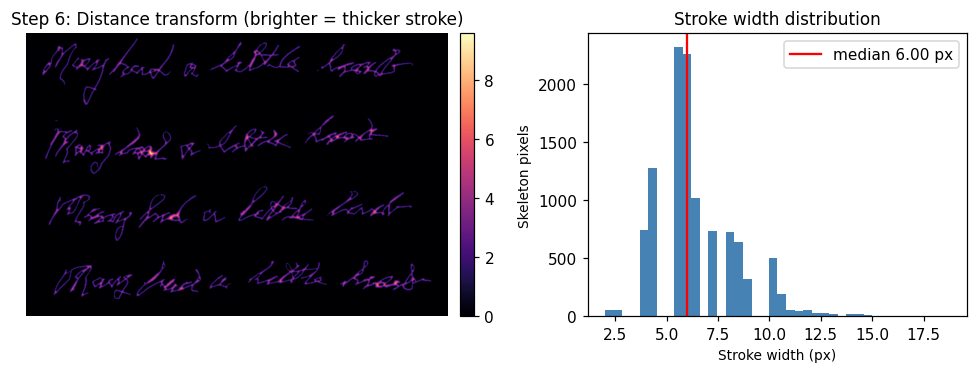

In [52]:
dist = cv2.distanceTransform(bw, cv2.DIST_L2, 5)
stroke_width = 2 * dist[y_all, x_all]          # full width in px at each skeleton pixel
median_sw = np.median(stroke_width)
print(f"Median stroke width: {median_sw:.2f} px")

fig, axes = plt.subplots(1, 2, figsize=(15, 3.5), gridspec_kw={"width_ratios": [3, 1]})
show_image(dist, "Step 6: Distance transform (brighter = thicker stroke)", cmap="magma",
           ax=axes[0], colorbar=True)
axes[1].hist(stroke_width, bins=40, color="steelblue")
axes[1].axvline(median_sw, color="red", label=f"median {median_sw:.2f} px")
axes[1].set_xlabel("Stroke width (px)"); axes[1].set_ylabel("Skeleton pixels")
axes[1].set_title("Stroke width distribution"); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Text line segmentation
Uses the **horizontal projection profile**: the number of ink pixels in each row.

- Text rows have lots of ink, gaps between lines have almost none.
- The profile is smoothed with a 5-row moving average.
- Rows above 10% of the peak count as "inside a line".
- Runs of such rows at least `min_line_height_px` tall become one text line `(y_start, y_end)`.

Left: the profile with the threshold. Right: detected line bands on the image.

Detected 4 text line(s): [(34, 128), (272, 362), (459, 543), (655, 745)]


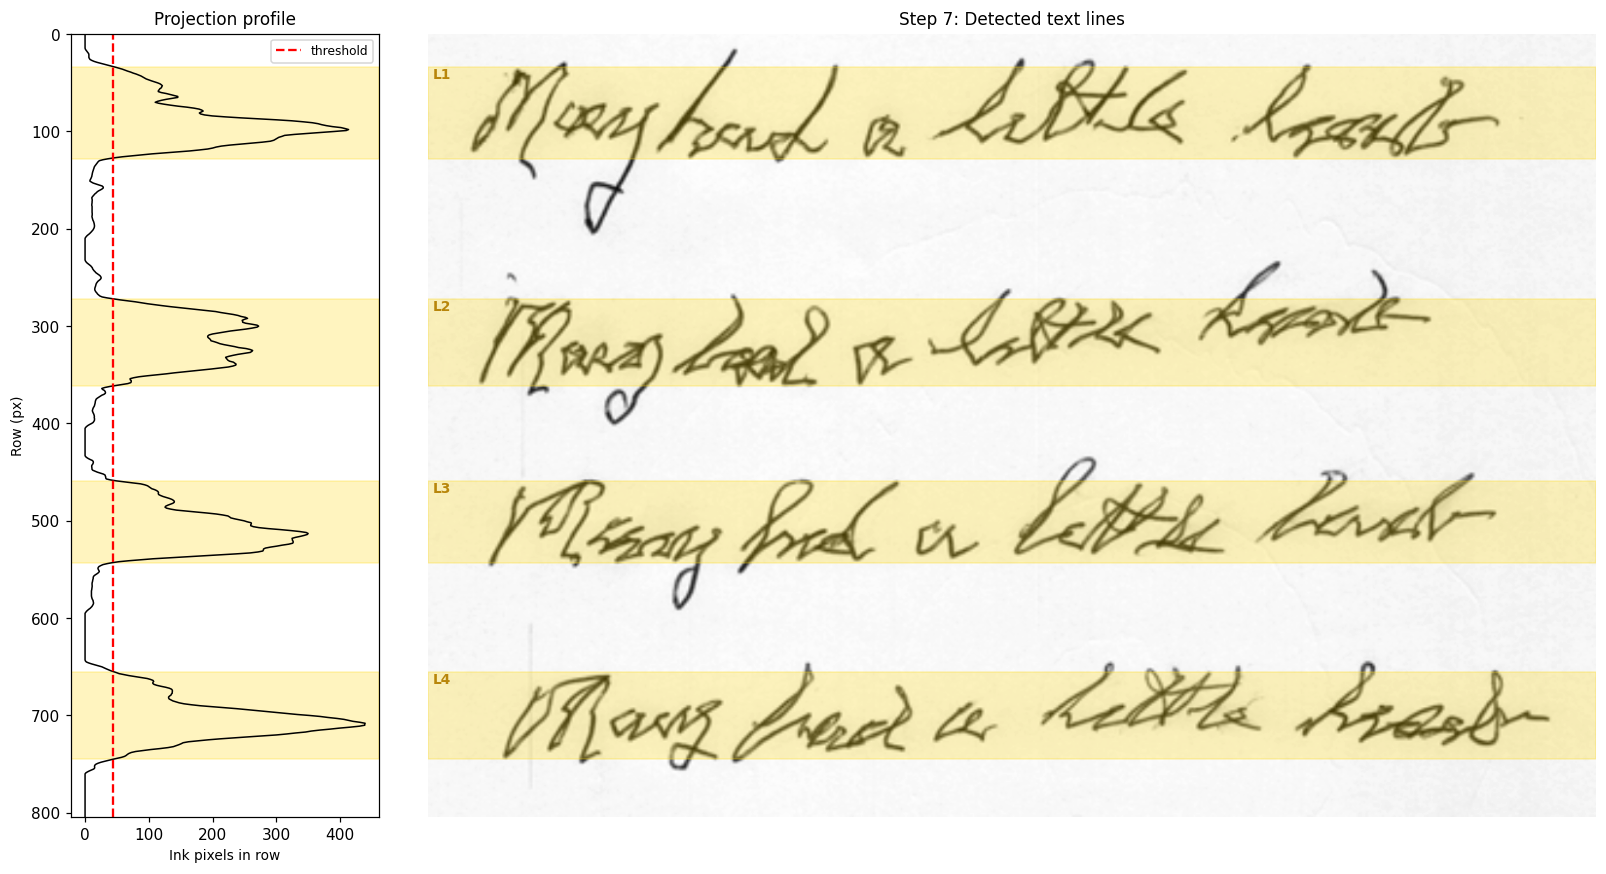

In [53]:
def segment_lines(bw_img, min_line_height_px=10):
    # Return (lines, smoothed_profile, threshold). lines = list of (y_start, y_end).
    row_ink = (bw_img > 0).sum(axis=1).astype(float)
    smooth  = np.convolve(row_ink, np.ones(5) / 5, mode="same")
    thresh  = smooth.max() * 0.1
    in_line = smooth > thresh

    lines, start = [], None
    for r, flag in enumerate(in_line):
        if flag and start is None:
            start = r
        elif not flag and start is not None:
            if r - start >= min_line_height_px:
                lines.append((start, r))
            start = None
    if start is not None and bw_img.shape[0] - start >= min_line_height_px:
        lines.append((start, bw_img.shape[0]))
    return lines, smooth, thresh

text_lines, row_profile, row_thresh = segment_lines(bw)
print(f"Detected {len(text_lines)} text line(s): {text_lines}")

fig, axes = plt.subplots(1, 2, figsize=(15, max(3, 12 * img.shape[0] / img.shape[1])),
                         gridspec_kw={"width_ratios": [1, 4]}, sharey=True)
axes[0].plot(row_profile, np.arange(len(row_profile)), color="black", lw=1)
axes[0].axvline(row_thresh, color="red", ls="--", label="threshold")
axes[0].set_xlabel("Ink pixels in row"); axes[0].set_ylabel("Row (px)")
axes[0].set_title("Projection profile"); axes[0].legend(fontsize=8)
show_image(img, "Step 7: Detected text lines", ax=axes[1])
for i, (y0, y1) in enumerate(text_lines):
    axes[1].axhspan(y0, y1, color="gold", alpha=0.25)
    axes[1].text(5, y0 + 12, f"L{i+1}", color="darkgoldenrod", fontsize=9, weight="bold")
    axes[0].axhspan(y0, y1, color="gold", alpha=0.25)
plt.tight_layout(); plt.show()

## 8. Blobs per line
Inside each line strip, every connected component of the skeleton is one blob: roughly a letter, or a joined group of letters.

OpenCV returns `[x, y, width, height, area]` per blob. We drop specks smaller than `MIN_BLOB_AREA`, shift `y` back to full-image coordinates and sort left to right. These blobs feed the spacing, baseline and slope features, so they are computed once and reused.


Line 1: 7 blobs kept, 1 noise specks removed
Line 2: 7 blobs kept, 0 noise specks removed
Line 3: 6 blobs kept, 0 noise specks removed
Line 4: 7 blobs kept, 0 noise specks removed


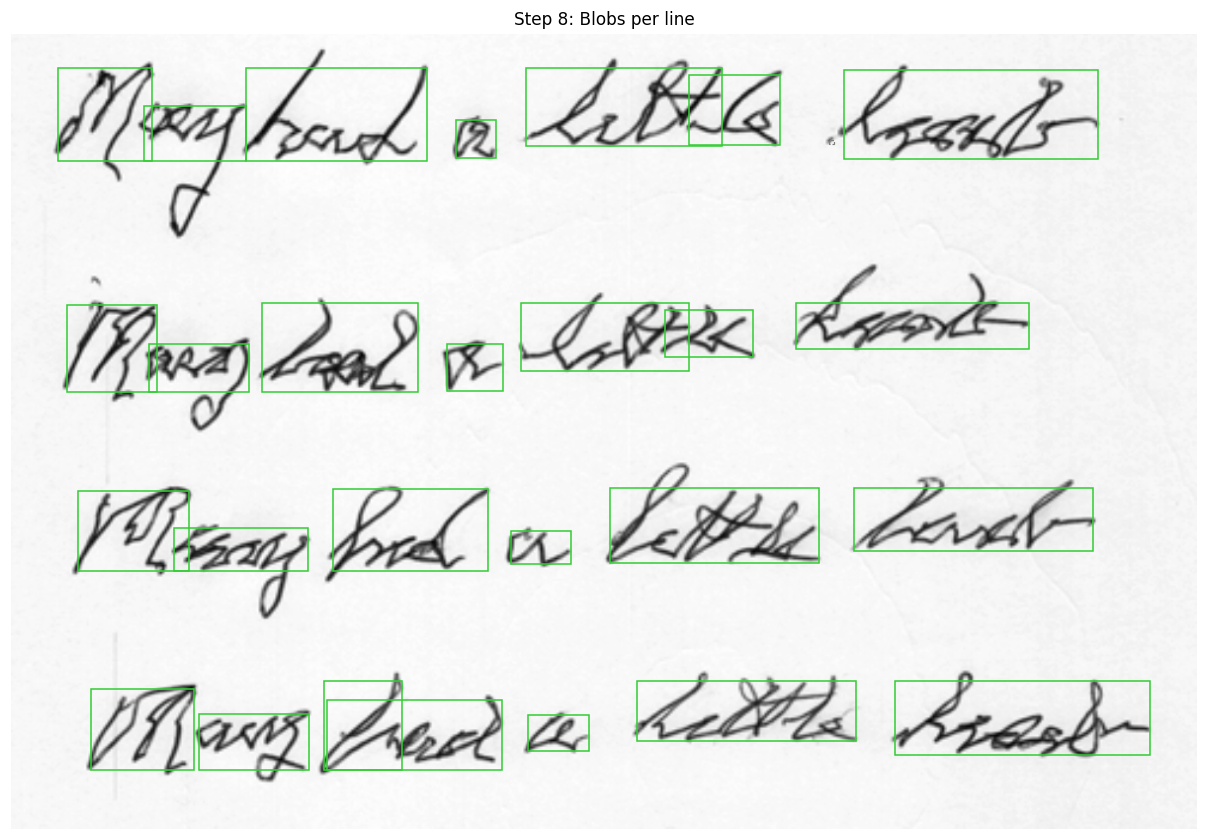

In [59]:
def line_blobs(y0, y1):
    # Returns (kept, rejected) bounding boxes [x, y, w, h, area], kept sorted left to right.
    _, _, st, _ = cv2.connectedComponentsWithStats(skeleton[y0:y1, :], connectivity=8)
    bbs = st[1:].copy()                 # row 0 is the background
    bbs[:, 1] += y0                     # strip coords -> image coords
    keep = bbs[:, 4] > MIN_BLOB_AREA
    kept = bbs[keep]
    return kept[np.argsort(kept[:, 0])], bbs[~keep]

blobs_per_line, rejected_per_line = zip(*[line_blobs(y0, y1) for (y0, y1) in text_lines]) \
    if text_lines else ([], [])
for i, (k, r) in enumerate(zip(blobs_per_line, rejected_per_line)):
    print(f"Line {i+1}: {len(k)} blobs kept, {len(r)} noise specks removed")

ax = show_image(img, "Step 8: Blobs per line")
for kept, rej in zip(blobs_per_line, rejected_per_line):
    for x, y, w, h, _ in kept:
        ax.add_patch(Rectangle((x, y), w, h, fill=False, ec="limegreen", lw=1))
    for x, y, w, h, _ in rej:
        ax.add_patch(Rectangle((x, y), w, h, fill=False, ec="gray", lw=0.8, ls="--"))
plt.show()

## 10. Features

### 10.1 Stroke width consistency
- sw_mean: average stroke width (px). T.
- sw_cv = std / mean: how inconsistent the thickness is (unitless).
- sw_range: P95 minus P5 width, a robust spread measure.

sw_mean = 6.46 px  |  sw_cv = 0.298  |  P5-P95 range = 6.00 px


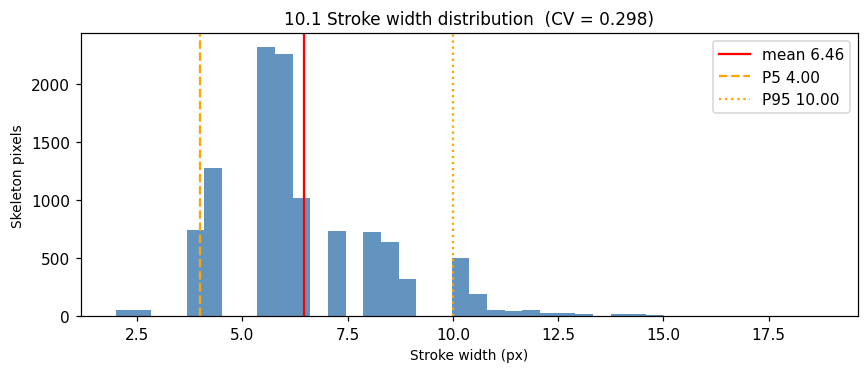

In [30]:
sw_mean  = stroke_width.mean()
sw_cv    = stroke_width.std() / (sw_mean + 1e-9)
sw_p5, sw_p95 = np.percentile(stroke_width, [5, 95])
sw_range = sw_p95 - sw_p5
print(f"sw_mean = {sw_mean:.2f} px  |  sw_cv = {sw_cv:.3f}  |  P5-P95 range = {sw_range:.2f} px")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(stroke_width, bins=40, color="steelblue", alpha=0.85)
ax.axvline(sw_mean, color="red", lw=1.5, label=f"mean {sw_mean:.2f}")
ax.axvline(sw_p5,  color="orange", ls="--", label=f"P5 {sw_p5:.2f}")
ax.axvline(sw_p95, color="orange", ls=":",  label=f"P95 {sw_p95:.2f}")
ax.set_xlabel("Stroke width (px)"); ax.set_ylabel("Skeleton pixels")
ax.set_title(f"10.1 Stroke width distribution  (CV = {sw_cv:.3f})"); ax.legend()
plt.tight_layout(); plt.show()

### 10.2 Baseline straightness and slope
For each line: take the **bottom edge** of every blob and fit a straight line (regression of bottom y on blob centre x).

- **Slope angle**: positive means the line *descends* to the right (image y grows downward).
- **Wobble**: std of the residuals in px, i.e. how much letters bounce off the baseline.
- **R²**: how well a straight line fits.

Plot: wobble per line (bars) and slope angle per line.

In [61]:
baseline_fits = []
for li, bbs in enumerate(blobs_per_line):
    if len(bbs) < 3:
        continue
    cx     = bbs[:, 0] + bbs[:, 2] / 2
    bottom = bbs[:, 1] + bbs[:, 3]
    fit    = stats.linregress(cx, bottom)
    resid  = bottom - (fit.slope * cx + fit.intercept)
    baseline_fits.append(dict(line=li, slope=fit.slope, intercept=fit.intercept,
                              cx=cx, bottom=bottom, angle_deg=np.degrees(np.arctan(fit.slope)),
                              wobble=resid.std(), r2=fit.rvalue**2))

if baseline_fits:
    baseline_wobble = np.mean([f["wobble"] for f in baseline_fits])
    baseline_r2     = np.mean([f["r2"] for f in baseline_fits])
    slope_deg       = np.mean([f["angle_deg"] for f in baseline_fits])
else:
    baseline_wobble = baseline_r2 = slope_deg = float("nan")
for f in baseline_fits:
    print(f"Line {f['line']+1}: slope {f['angle_deg']:+.2f} deg  |  wobble {f['wobble']:.2f} px  |  R2 {f['r2']:.3f}")

# if baseline_fits:
#     labels = [f"L{f['line']+1}" for f in baseline_fits]
#     fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
#     axes[0].bar(labels, [f["wobble"] for f in baseline_fits], color="teal")
#     axes[0].axhline(baseline_wobble, color="red", ls="--", label=f"mean {baseline_wobble:.2f} px")
#     axes[0].set_ylabel("Wobble (px)"); axes[0].set_title("10.4 Baseline wobble per line"); axes[0].legend()
#     axes[1].bar(labels, [f["angle_deg"] for f in baseline_fits], color="indianred")
#     axes[1].axhline(0, color="black", lw=0.8)
#     axes[1].set_ylabel("Angle (deg, + = descending)"); axes[1].set_title("Baseline slope per line")
#     plt.tight_layout(); plt.show()

Line 1: slope -0.68 deg  |  wobble 5.70 px  |  R2 0.262
Line 2: slope -3.39 deg  |  wobble 6.85 px  |  R2 0.843
Line 3: slope -1.34 deg  |  wobble 2.56 px  |  R2 0.873
Line 4: slope -1.68 deg  |  wobble 7.72 px  |  R2 0.537


### 10.3 Spacing between words / letter groups
Within each line, gap = left edge of the next blob minus right edge of the current blob. Gaps of `MIN_GAP_PX` or less are skipped.
- `gap_mean`: typical spacing (px).
- `gap_cv`: spacing irregularity. Very uneven spacing can reflect festination.

In [60]:
gap_records = []    # (line_index, x_left, x_right, gap_px)
for li, bbs in enumerate(blobs_per_line):
    if len(bbs) < 2:
        continue
    for r_edge, l_edge in zip(bbs[:-1, 0] + bbs[:-1, 2], bbs[1:, 0]):
        gap = int(l_edge) - int(r_edge)
        if gap > MIN_GAP_PX:
            gap_records.append((li, int(r_edge), int(l_edge), gap))

all_gaps = np.array([g[3] for g in gap_records], dtype=float)
if len(all_gaps) > 1:
    gap_mean = all_gaps.mean()
    gap_cv   = all_gaps.std() / (gap_mean + 1e-9)
else:
    gap_mean = gap_cv = float("nan")
print(f"{len(all_gaps)} gaps  |  gap_mean = {gap_mean:.1f} px  |  gap_cv = {gap_cv:.3f}")

# if len(all_gaps):
#     fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
#     axes[0].hist(all_gaps, bins=25, color="darkorange")
#     axes[0].axvline(gap_mean, color="red", label=f"mean {gap_mean:.1f} px")
#     axes[0].set_xlabel("Gap (px)"); axes[0].set_ylabel("Count")
#     axes[0].set_title(f"10.5 Gap distribution  (CV = {gap_cv:.3f})"); axes[0].legend()
#     for li in sorted(set(g[0] for g in gap_records)):
#         g = [r[3] for r in gap_records if r[0] == li]
#         axes[1].plot(range(1, len(g) + 1), g, "o-", ms=3, label=f"L{li+1}")
#     axes[1].set_xlabel("Gap number (left to right)"); axes[1].set_ylabel("Gap (px)")
#     axes[1].set_title("Gaps along each line"); axes[1].legend(fontsize=8)
#     plt.tight_layout(); plt.show()

16 gaps  |  gap_mean = 30.7 px  |  gap_cv = 0.463


## 11. Result plot 1: Traces
The skeleton drawn on the original image, each pixel coloured by stroke width (blue = thin, red = thick). Colours are clipped to the P5 to P95 range so a few outliers do not wash out the scale.

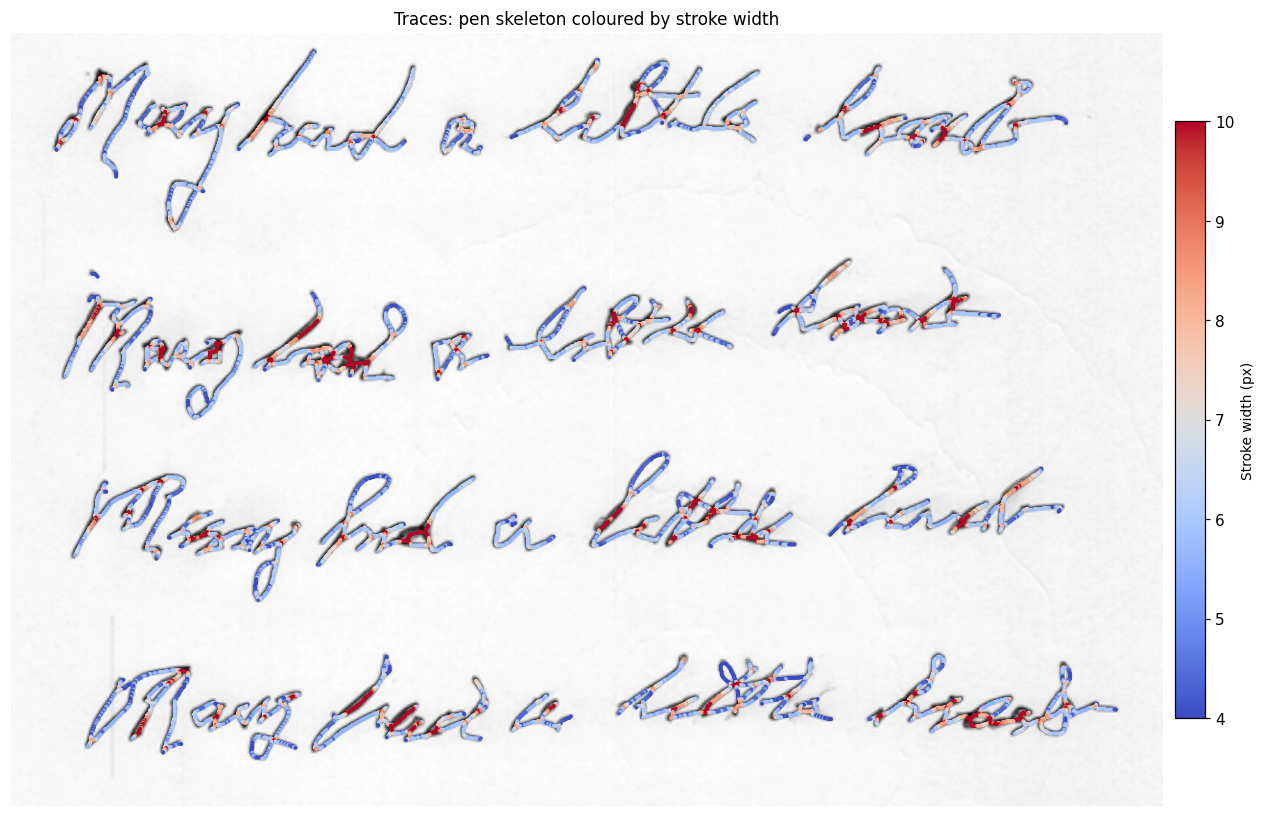

In [17]:
ax = show_image(img, "Traces: pen skeleton coloured by stroke width")
sc = ax.scatter(x_all, y_all, c=stroke_width, cmap="coolwarm", s=2,
                vmin=sw_p5, vmax=sw_p95)
plt.colorbar(sc, ax=ax, fraction=0.025, pad=0.01, label="Stroke width (px)")
# plt.savefig("traces.png", dpi=180, bbox_inches="tight")
plt.show()

## 14. Result plot 2: Word distance
Every measured gap between neighbouring blobs is shaded orange and labelled with its width in px. Blob boxes are shown in light green for context.

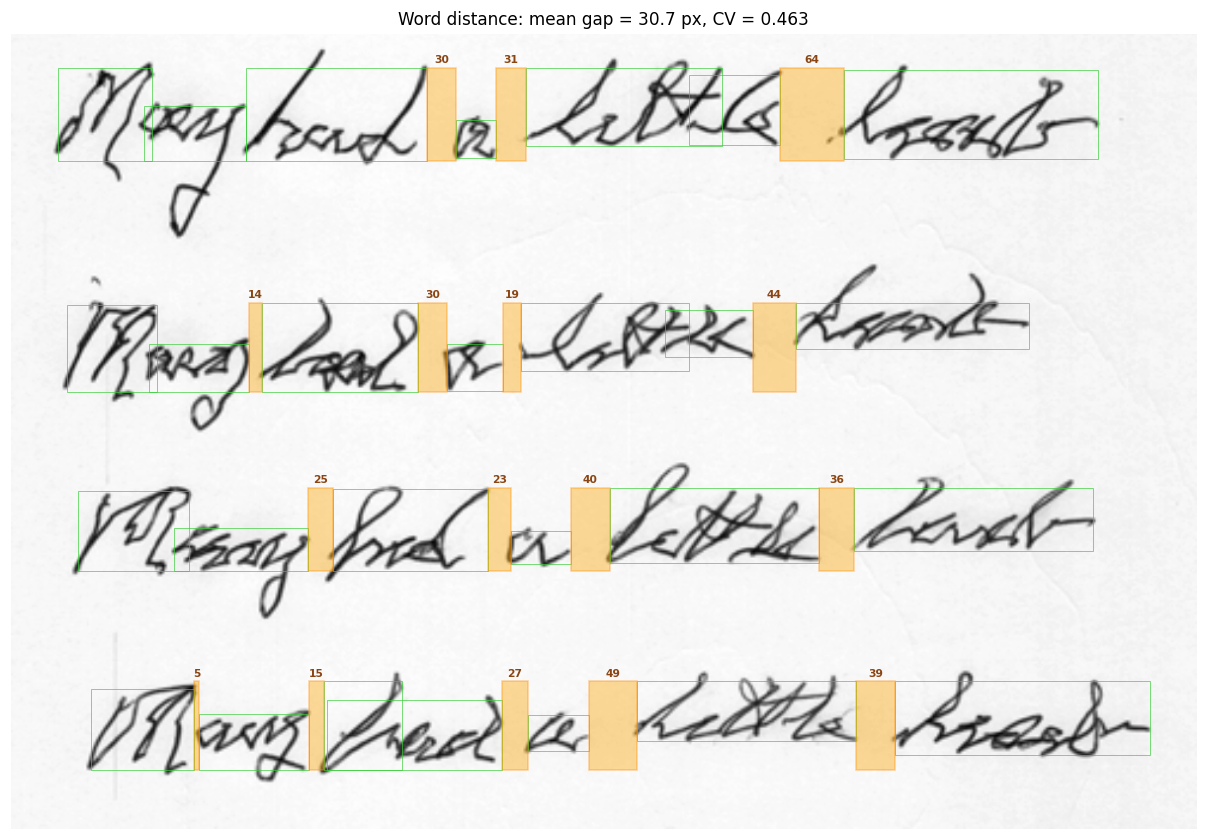

In [18]:
ax = show_image(img, f"Word distance: mean gap = {gap_mean:.1f} px, CV = {gap_cv:.3f}")
for bbs in blobs_per_line:
    for x, y, w, h, _ in bbs:
        ax.add_patch(Rectangle((x, y), w, h, fill=False, ec="limegreen", lw=0.6, alpha=0.7))
for li, x_left, x_right, gap_px in gap_records:
    y0, y1 = text_lines[li]
    ax.add_patch(Rectangle((x_left, y0), x_right - x_left, y1 - y0,
                           fc="orange", ec="darkorange", alpha=0.4, lw=1))
    ax.text((x_left + x_right) / 2, y0 - 3, f"{gap_px}", ha="center", va="bottom",
            fontsize=7, color="saddlebrown", weight="bold")
# plt.savefig("word_distance.png", dpi=180, bbox_inches="tight")
plt.show()

## 15. Result plot 3: Slope
For each line: blob bottoms (blue dots), the fitted baseline (red line) with its **angle**, and residual sticks (cyan) showing how far each letter sits off the baseline. Long sticks = high wobble.

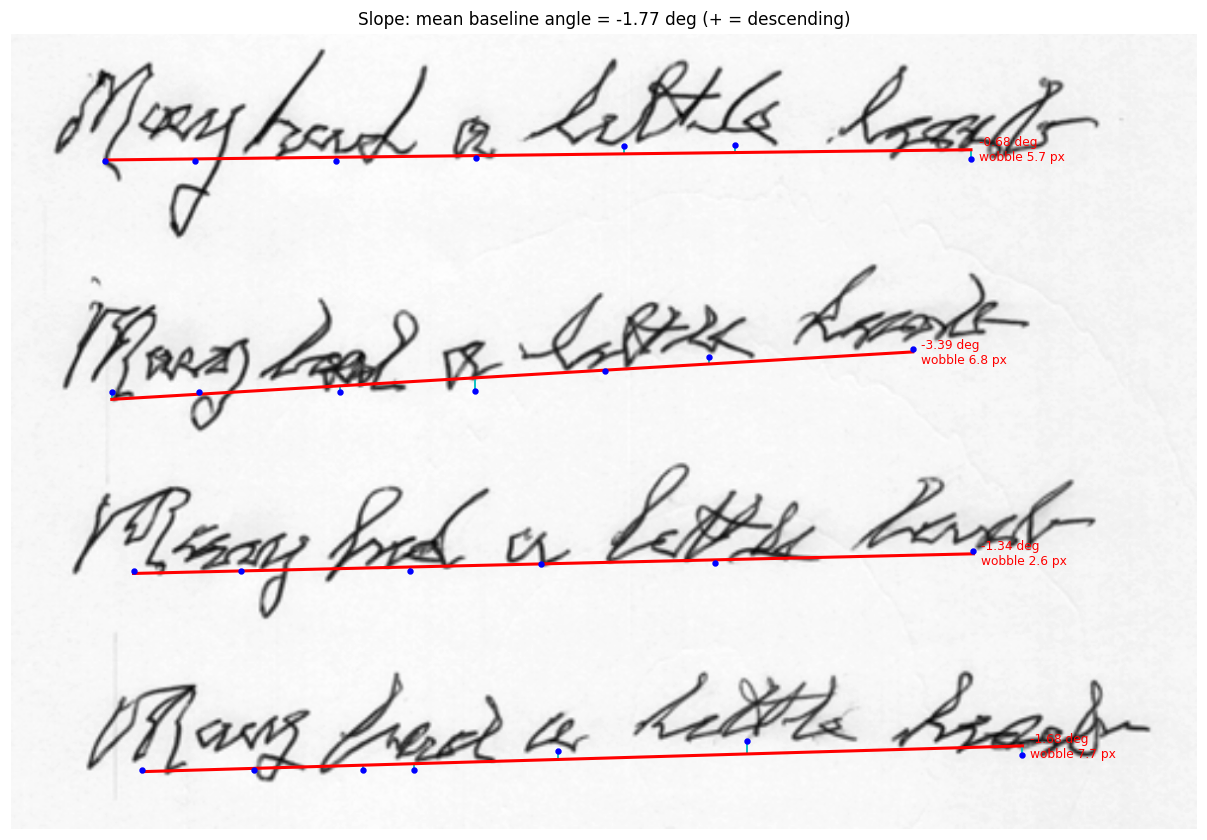

In [19]:
ax = show_image(img, f"Slope: mean baseline angle = {slope_deg:+.2f} deg (+ = descending)")
for f in baseline_fits:
    xs = np.array([f["cx"].min(), f["cx"].max()])
    ys = f["slope"] * xs + f["intercept"]
    fitted = f["slope"] * f["cx"] + f["intercept"]
    ax.vlines(f["cx"], fitted, f["bottom"], color="c", lw=1.2)
    ax.scatter(f["cx"], f["bottom"], color="blue", s=10, zorder=3)
    ax.plot(xs, ys, color="red", lw=2)
    ax.text(xs[1] + 8, ys[1], f"{f['angle_deg']:+.2f} deg\nwobble {f['wobble']:.1f} px",
            color="red", fontsize=8, va="center")
# plt.savefig("slope.png", dpi=180, bbox_inches="tight")
plt.show()

# Conclusion

The preliminary results demonstrate how handwriting images can be processed to extract quantitative features such as trace characteristics, word spacing, and writing slope, providing a foundation for objective analysis of handwriting patterns associated with Parkinson’s disease (PD). These measurements may help characterize motor-related changes, including micrographia, irregular spacing, variations in writing direction, and impaired fine-motor control. 

Furthermore, these primary features can be used to derive additional metrics, such as spacing variability, line-to-line slope changes, trace curvature, tremor-related oscillations, stroke-width variability, and spatial consistency, depending on the research objectives. Combining these features with measurements from other handwriting tasks, such as spiral drawing, and clinical assessment scores could provide a more comprehensive representation of motor performance. Statistical analysis and machine-learning techniques can then be used to investigate relationships between extracted features and clinical severity, identify potentially informative patterns, and evaluate their usefulness for PD-related research. 

Overall, this modular pipeline provides an extensible foundation for handwriting analysis, with further validation required to establish feature reliability, clinical relevance, and potential utility as part of a broader clinical assessment framework.